## 1. Install and Import Required Libraries

### What are we doing?
We first make sure the required Python packages are available and then import them.

### Why are we doing it?
Your VS Code setup may not have the machine-learning libraries installed. This cell installs the packages used in this notebook so that the project can be executed in a clean Python environment.

### What will the output mean?
A successful message means the environment is ready for the remaining cells.


In [ ]:
# Run this cell first.
# It installs only the packages required for this project.

import sys
import subprocess

packages = ["pandas", "numpy", "matplotlib", "scikit-learn"]

for package in packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-U", package])

print("Required packages installed successfully.")

# Imports used throughout the notebook
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All imports completed successfully.")


Required packages installed successfully.
All imports completed successfully.


## 2. Load the Earthquake Dataset

### What are we doing?
We load the supplied `Earthquake.csv.csv` file into a Pandas DataFrame.

### Why are we doing it?
All later analysis and modeling depends on having the dataset available in memory.

### What will the output mean?
The shape tells us the number of observations and variables. The first rows show the actual data, while the data types help us identify numerical, categorical, and date/time fields.


In [ ]:
# Try the common filenames first.
# If neither exists, a Windows file-selection window will open.

from pathlib import Path
import pandas as pd

possible_files = [
    Path(r"C:\Users\prava\Downloads\Earthquake.csv"),
    Path(r"C:\Users\prava\Downloads\Earthquake.csv.csv"),
    Path.cwd() / "Earthquake.csv",
    Path.cwd() / "Earthquake.csv.csv",
]

DATA_PATH = next((p for p in possible_files if p.is_file()), None)

if DATA_PATH is None:
    # No hard-coded file was found, so let you select the CSV manually.
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    selected = filedialog.askopenfilename(
        title="Select your Earthquake CSV file",
        filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
    )

    root.destroy()

    if not selected:
        raise FileNotFoundError(
            "No dataset was selected. Run this cell again and select Earthquake.csv."
        )

    DATA_PATH = Path(selected)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("File:", DATA_PATH)
print("Shape:", df.shape)

display(df.head())
display(df.dtypes)


Dataset loaded successfully.
File: C:\Users\prava\Downloads\Earthquake.csv.csv
Shape: (23412, 21)


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


Date                              str
Time                              str
Latitude                      float64
Longitude                     float64
Type                              str
Depth                         float64
Depth Error                   float64
Depth Seismic Stations        float64
Magnitude                     float64
Magnitude Type                    str
Magnitude Error               float64
Magnitude Seismic Stations    float64
Azimuthal Gap                 float64
Horizontal Distance           float64
Horizontal Error              float64
Root Mean Square              float64
ID                                str
Source                            str
Location Source                   str
Magnitude Source                  str
Status                            str
dtype: object

## 3. Dataset Understanding

### What are we doing?
We inspect the dataset dimensions, column names, data types, and summary statistics.

### Why are we doing it?
Understanding the variables is necessary before selecting features and choosing preprocessing methods.

### What will the output mean?
The output documents the structure of the dataset and helps identify columns such as identifiers, measurements, categorical fields, and timestamp fields.


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nNumerical summary:")
display(df.describe().T)


Number of rows: 23412
Number of columns: 21

Column names:
1. Date
2. Time
3. Latitude
4. Longitude
5. Type
6. Depth
7. Depth Error
8. Depth Seismic Stations
9. Magnitude
10. Magnitude Type
11. Magnitude Error
12. Magnitude Seismic Stations
13. Azimuthal Gap
14. Horizontal Distance
15. Horizontal Error
16. Root Mean Square
17. ID
18. Source
19. Location Source
20. Magnitude Source
21. Status

Data types:


,Data Type
Date,str
Time,str
Latitude,float64
Longitude,float64
Type,str
Depth,float64
Depth Error,float64
Depth Seismic Stations,float64
Magnitude,float64
Magnitude Type,str



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Latitude,23412.0,1.679033,30.113183,-77.080000,-18.65300,-3.5685,26.19075,86.005
Longitude,23412.0,39.639961,125.511959,-179.997000,-76.34975,103.9820,145.02625,179.998
Depth,23412.0,70.767911,122.651898,-1.100000,14.52250,33.0000,54.00000,700.000
Depth Error,4461.0,4.993115,4.875184,0.000000,1.80000,3.5000,6.30000,91.295
Depth Seismic Stations,7097.0,275.364098,162.141631,0.000000,146.00000,255.0000,384.00000,934.000
Magnitude,23412.0,5.882531,0.423066,5.500000,5.60000,5.7000,6.00000,9.100
Magnitude Error,327.0,0.071820,0.051466,0.000000,0.04600,0.0590,0.07550,0.410
Magnitude Seismic Stations,2564.0,48.944618,62.943106,0.000000,10.00000,28.0000,66.00000,821.000
Azimuthal Gap,7299.0,44.163532,32.141486,0.000000,24.10000,36.0000,54.00000,360.000
Horizontal Distance,1604.0,3.992660,5.377262,0.004505,0.96875,2.3195,4.72450,37.874


## 4. Define the Prediction Problem and Target

### What are we doing?
We define `Magnitude` as the only target variable.

### Why are we doing it?
Magnitude is a continuous numerical quantity, so predicting it is a **regression problem**. The assignment asks for a prediction project, and the goal is to estimate earthquake magnitude from available earthquake attributes.

### What will the output mean?
The target statistics show the range, average, and variability of magnitude values in the dataset.


In [ ]:
TARGET = "Magnitude"

if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' was not found.")

y = df[TARGET]

print("Target variable:", TARGET)
print("Machine-learning problem: Regression")
display(y.describe())


Target variable: Magnitude
Machine-learning problem: Regression


count    23412.000000
mean         5.882531
std          0.423066
min          5.500000
25%          5.600000
50%          5.700000
75%          6.000000
max          9.100000
Name: Magnitude, dtype: float64

## 5. Missing Value Analysis

### What are we doing?
We count missing observations in every column.

### Why are we doing it?
Many machine-learning algorithms cannot directly process missing values. We therefore need to understand the amount and location of missing data before preprocessing.

### What will the output mean?
The table shows the number and percentage of missing values in each variable. Columns with substantial missingness will be handled through the preprocessing pipeline rather than by arbitrary deletion.


In [ ]:
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent
}).sort_values("Missing Values", ascending=False)

display(missing_table)


,Missing Values,Missing Percentage
Magnitude Error,23085,98.60
Horizontal Error,22256,95.06
Horizontal Distance,21808,93.15
Magnitude Seismic Stations,20848,89.05
Depth Error,18951,80.95
Depth Seismic Stations,16315,69.69
Azimuthal Gap,16113,68.82
Root Mean Square,6060,25.88
Magnitude Type,3,0.01
Date,0,0.00


## 6. Duplicate Analysis

### What are we doing?
We check whether the dataset contains completely duplicated rows.

### Why are we doing it?
Duplicate records can give repeated observations disproportionate influence during training and can distort descriptive analysis.

### What will the output mean?
If duplicates exist, they are removed. If the count is zero, the original dataset is retained.


In [ ]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed.")
else:
    print("No duplicate rows were found.")


Duplicate rows found: 0
No duplicate rows were found.


## 7. Outlier Analysis

### What are we doing?
We inspect the numerical variables with boxplots and use the IQR rule to identify potentially extreme observations.

### Why are we doing it?
Outliers can affect some algorithms. However, an extreme earthquake magnitude or measurement can be a genuine observation rather than an error. Therefore, we identify outliers but do **not** blindly delete them.

### What will the output mean?
The IQR table reports the number of observations outside the conventional lower and upper bounds. The boxplots visually show the spread and possible extreme values.


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
2,Depth,14.52250,54.00000,39.47750,-44.693750,113.216250,3274
5,Magnitude,5.60000,6.00000,0.40000,5.000000,6.600000,1475
8,Azimuthal Gap,24.10000,54.00000,29.90000,-20.750000,98.850000,378
11,Root Mean Square,0.90000,1.13000,0.23000,0.555000,1.475000,308
3,Depth Error,1.80000,6.30000,4.50000,-4.950000,13.050000,271
7,Magnitude Seismic Stations,10.00000,66.00000,56.00000,-74.000000,150.000000,149
9,Horizontal Distance,0.96875,4.72450,3.75575,-4.664875,10.358125,123
10,Horizontal Error,5.30000,8.10000,2.80000,1.100000,12.300000,85
4,Depth Seismic Stations,146.00000,384.00000,238.00000,-211.000000,741.000000,36
6,Magnitude Error,0.04600,0.07550,0.02950,0.001750,0.119750,33


C:\Users\prava\AppData\Local\Temp\ipykernel_24060\1732305896.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[TARGET].dropna(), vert=False)


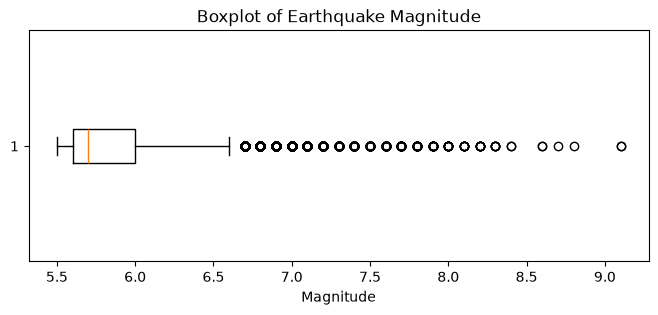

In [ ]:
numeric_columns_all = df.select_dtypes(include=np.number).columns.tolist()

iqr_rows = []

for col in numeric_columns_all:
    values = df[col].dropna()
    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((values < lower) | (values > upper)).sum()

    iqr_rows.append([col, q1, q3, iqr, lower, upper, int(count)])

outlier_table = pd.DataFrame(
    iqr_rows,
    columns=["Feature", "Q1", "Q3", "IQR", "Lower Bound", "Upper Bound", "Potential Outliers"]
)

display(outlier_table.sort_values("Potential Outliers", ascending=False))

# Plot the target outlier distribution separately.
plt.figure(figsize=(8, 3))
plt.boxplot(df[TARGET].dropna(), vert=False)
plt.xlabel("Magnitude")
plt.title("Boxplot of Earthquake Magnitude")
plt.show()


## 8. Exploratory Data Analysis — Magnitude Distribution

### What are we doing?
We plot the distribution of earthquake magnitude.

### Why are we doing it?
The target distribution helps us understand how common different magnitude ranges are and whether the data is strongly concentrated or skewed.

### What will the output mean?
The histogram shows the frequency of earthquakes across magnitude ranges.


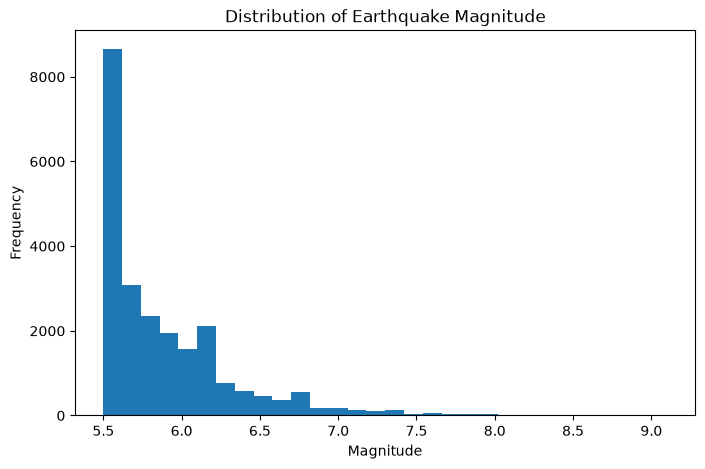

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df[TARGET].dropna(), bins=30)
plt.xlabel("Magnitude")
plt.ylabel("Frequency")
plt.title("Distribution of Earthquake Magnitude")
plt.show()


## 9. Exploratory Data Analysis — Correlation

### What are we doing?
We calculate the correlation of numerical variables with Magnitude.

### Why are we doing it?
Correlation is a useful first screening method for understanding linear relationships between numerical predictors and the target.

### What will the output mean?
Values closer to +1 or -1 represent stronger linear relationships. Correlation is only exploratory and does not establish causation.


In [ ]:
numeric_df = df.select_dtypes(include=np.number)
correlation_with_target = numeric_df.corr(numeric_only=True)[[TARGET]].sort_values(
    TARGET, ascending=False
)

display(correlation_with_target)


,Magnitude
Magnitude,1.000000
Depth Seismic Stations,0.440582
Magnitude Error,0.135573
Root Mean Square,0.075865
Longitude,0.038579
Latitude,0.034987
Depth,0.023457
Magnitude Seismic Stations,-0.003972
Horizontal Error,-0.078406
Horizontal Distance,-0.092609


## 10. Exploratory Data Analysis — Geographic Pattern

### What are we doing?
We visualize earthquakes using Latitude and Longitude when those variables are available.

### Why are we doing it?
Earthquakes have a geographic component. A spatial plot can reveal clusters and broad patterns that may not be visible in a table.

### What will the output mean?
Each point represents an earthquake location, with the magnitude represented by the point's value.


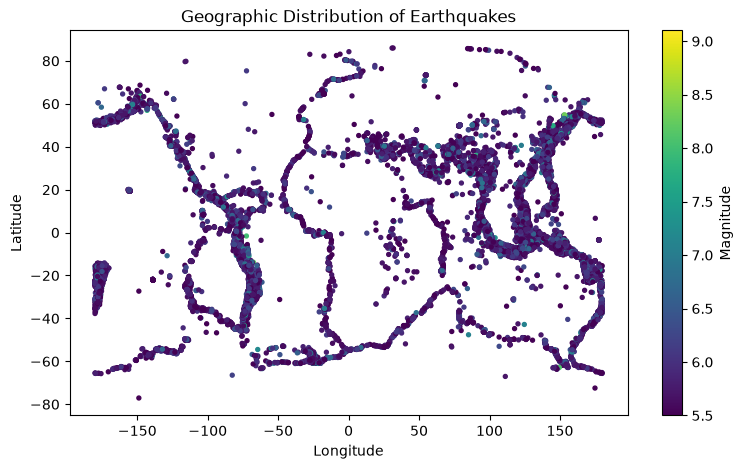

In [ ]:
if {"Latitude", "Longitude"}.issubset(df.columns):
    plt.figure(figsize=(9, 5))
    plt.scatter(
        df["Longitude"],
        df["Latitude"],
        c=df[TARGET],
        s=8
    )
    plt.colorbar(label="Magnitude")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Geographic Distribution of Earthquakes")
    plt.show()
else:
    print("Latitude and Longitude are not available in this dataset.")


## 11. Feature Engineering — Date and Time

### What are we doing?
We convert the raw Date and Time columns into numerical components such as year, month, day, hour, minute, and second.

### Why are we doing it?
Raw timestamp strings are not directly useful to most regression algorithms. Extracting meaningful components makes temporal information available to the model.

### What will the output mean?
The new temporal columns become candidate predictors, while the original Date and Time strings are later excluded from the model matrix.


In [ ]:
work = df.copy()

if "Date" in work.columns:
    date_values = pd.to_datetime(work["Date"], errors="coerce")
    work["Year"] = date_values.dt.year
    work["Month"] = date_values.dt.month
    work["Day"] = date_values.dt.day

if "Time" in work.columns:
    time_parts = work["Time"].astype(str).str.extract(
        r"(?P<Hour>\d{1,2}):(?P<Minute>\d{1,2}):(?P<Second>\d{1,2})"
    )

    for col in ["Hour", "Minute", "Second"]:
        work[col] = pd.to_numeric(time_parts[col], errors="coerce")

display(work.head())


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Source,Location Source,Magnitude Source,Status,Year,Month,Day,Hour,Minute,Second
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,ISCGEM,ISCGEM,ISCGEM,Automatic,1965.0,1.0,2.0,13,44,18
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,ISCGEM,ISCGEM,ISCGEM,Automatic,1965.0,1.0,4.0,11,29,49
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,ISCGEM,ISCGEM,ISCGEM,Automatic,1965.0,1.0,5.0,18,5,58
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,ISCGEM,ISCGEM,ISCGEM,Automatic,1965.0,1.0,8.0,18,49,43
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,ISCGEM,ISCGEM,ISCGEM,Automatic,1965.0,1.0,9.0,13,32,50


## 12. Feature Selection

### What are we doing?
We construct `X` using the predictive variables and `y` using Magnitude.

### Why are we doing it?
The target must never be included as a predictor. `ID` is an identifier rather than a physical measurement. Raw Date and Time are excluded because their useful information has already been represented by engineered components.

### What will the output mean?
The feature list documents exactly which variables are supplied to the machine-learning models.


In [ ]:
drop_columns = [TARGET]

for col in ["ID", "Date", "Time"]:
    if col in work.columns:
        drop_columns.append(col)

X = work.drop(columns=drop_columns)
y = work[TARGET]

valid_target = y.notna()
X = X.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].reset_index(drop=True)

print("Selected features:")
print(X.columns.tolist())
print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)


Selected features:
['Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error', 'Depth Seismic Stations', 'Magnitude Type', 'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap', 'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'Source', 'Location Source', 'Magnitude Source', 'Status', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'Second']

Feature matrix shape: (23412, 23)
Target shape: (23412,)


## 13. Train-Test Split

### What are we doing?
We divide the data into an 80% training set and a 20% test set.

### Why are we doing it?
The model learns from the training data. The test data remains unseen until evaluation so that final performance represents generalization to unseen observations.

### What will the output mean?
The printed shapes confirm how many observations are used for training and final testing.


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (18729, 23)
X_test : (4683, 23)
y_train: (18729,)
y_test : (4683,)


## 14. Data Preprocessing

### What are we doing?
We build a preprocessing pipeline for numerical and categorical features.

### Why are we doing it?
Numerical variables may contain missing values and can have very different scales. Categorical variables must be encoded before most regression algorithms can use them. The preprocessing is fitted only on training data to avoid test-set leakage.

### What will the output mean?
`X_train_processed` and `X_test_processed` are numerical matrices ready for machine-learning algorithms.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(include="object").columns.tolist()

transformers = []

if numeric_columns:
    transformers.append(
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_columns
        )
    )

if categorical_columns:
    # sparse_output=False is used by current scikit-learn versions.
    transformers.append(
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_columns
        )
    )

preprocessor = ColumnTransformer(transformers=transformers)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed.")
print("Processed X_train:", X_train_processed.shape)
print("Processed X_test :", X_test_processed.shape)


C:\Users\prava\AppData\Local\Temp\ipykernel_24060\2889052581.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(include="object").columns.tolist()


Preprocessing completed.
Processed X_train: (18729, 114)
Processed X_test : (4683, 114)


## 15. Model Development

### What are we doing?
We train several regression algorithms: Linear Regression, Ridge Regression, Decision Tree, Random Forest, Gradient Boosting, SVR, and KNN.

### Why are we doing it?
Different algorithms make different assumptions and capture different types of relationships. Comparing them helps identify an appropriate model for the dataset. Ridge is included because it provides regularization.

### What will the output mean?
MAE and RMSE measure prediction error, so lower is better. R² measures explained variance, so higher is generally better.


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "SVR": SVR(kernel="rbf"),
    "KNN": KNeighborsRegressor(n_neighbors=7)
}

model_rows = []
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)
    pred = model.predict(X_test_processed)
    predictions[name] = pred

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    model_rows.append([name, mae, rmse, r2])

model_results = pd.DataFrame(
    model_rows,
    columns=["Model", "MAE", "RMSE", "R2"]
).sort_values(
    "R2",
    ascending=False
).reset_index(drop=True)

print("Model Comparison Results:")
display(model_results)


Training Linear Regression...
Training Ridge Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training SVR...
Training KNN...
Model Comparison Results:


,Model,MAE,RMSE,R2
0,Random Forest,0.262922,0.367517,0.267708
1,Gradient Boosting,0.266688,0.374652,0.238997
2,SVR,0.255074,0.382240,0.207862
3,Ridge Regression,0.279178,0.387262,0.186910
4,Linear Regression,0.279203,0.387558,0.185664
5,Decision Tree,0.276557,0.394031,0.158237
6,KNN,0.287568,0.403230,0.118477


## 16. Model Validation — Five-Fold Cross-Validation

### What are we doing?
We apply five-fold cross-validation to compare model stability using the training data.

### Why are we doing it?
A single split can sometimes give an unstable estimate. Cross-validation evaluates the models over multiple validation partitions.

### What will the output mean?
Mean CV MAE is the average absolute error across folds. Lower values indicate better average validation performance. The standard deviation indicates how much the error varies between folds.


In [ ]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_rows = []

for name, model in models.items():
    scores = -cross_val_score(
        model,
        X_train_processed,
        y_train,
        cv=kf,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    cv_rows.append([
        name,
        scores.mean(),
        scores.std()
    ])

cv_results = pd.DataFrame(
    cv_rows,
    columns=["Model", "Mean CV MAE", "Std CV MAE"]
).sort_values(
    "Mean CV MAE"
).reset_index(drop=True)

display(cv_results)


In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm

from sklearn.model_selection import train_test_split


pval_df = pd.read_csv(
    r"C:\Users\prava\Downloads\Earthquake.csv.csv"
)

print("Dataset loaded successfully.")
print("Shape:", pval_df.shape)



pval_target = pval_df["Magnitude"]

# Select only numerical predictor columns.
# This avoids changing or interfering with your current
# preprocessing/model pipeline.

pval_features = pval_df.select_dtypes(
    include=np.number
).drop(
    columns=["Magnitude"],
    errors="ignore"
)

pval_features = pval_features.fillna(
    pval_features.median()
)


pval_valid = pval_target.notna()

pval_features = pval_features.loc[pval_valid]
pval_target = pval_target.loc[pval_valid]



pval_features = sm.add_constant(
    pval_features,
    has_constant="add"
)



pval_ols = sm.OLS(
    pval_target,
    pval_features
).fit()



print(pval_ols.summary())


pval_table = pd.DataFrame({
    "Feature": pval_ols.params.index,
    "Coefficient": pval_ols.params.values,
    "P-Value": pval_ols.pvalues.values
})


pval_table["Significant (p < 0.05)"] = (
    pval_table["P-Value"] < 0.05
)


pval_table = pval_table.sort_values(
    "P-Value"
).reset_index(drop=True)


print("\nP-VALUE TABLE")
print("=" * 70)

display(pval_table)

print("\nOVERALL MODEL STATISTICS")
print("=" * 70)

print(
    "R²:",
    round(pval_ols.rsquared, 4)
)

print(
    "Adjusted R²:",
    round(pval_ols.rsquared_adj, 4)
)

print(
    "F-statistic:",
    round(pval_ols.fvalue, 4)
)

print(
    "Overall Model P-value:",
    pval_ols.f_pvalue
)

Dataset loaded successfully.
Shape: (23412, 21)
                            OLS Regression Results                            
Dep. Variable:              Magnitude   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     170.5
Date:                Tue, 01 Sep 2026   Prob (F-statistic):               0.00
Time:                        11:50:56   Log-Likelihood:                -12178.
No. Observations:               23412   AIC:                         2.438e+04
Df Residuals:                   23400   BIC:                         2.448e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------

,Feature,Coefficient,P-Value,Significant (p < 0.05)
0,const,5.378650,0.000000e+00,True
1,Depth Seismic Stations,0.001125,3.672701e-252,True
2,Root Mean Square,0.219896,2.681597e-37,True
3,Magnitude Seismic Stations,-0.000801,1.223695e-10,True
4,Depth Error,-0.008067,4.810518e-10,True
5,Longitude,0.000131,3.261313e-09,True
6,Azimuthal Gap,-0.000879,1.286442e-07,True
7,Horizontal Distance,-0.006245,7.389432e-04,True
8,Magnitude Error,1.330465,9.634476e-03,True
9,Latitude,-0.000124,1.993346e-01,False



OVERALL MODEL STATISTICS
R²: 0.0742
Adjusted R²: 0.0738
F-statistic: 170.4722
Overall Model P-value: 0.0


## 17. Hyperparameter Tuning

### What are we doing?
We tune the Random Forest model using GridSearchCV.

### Why are we doing it?
Random Forest performance depends on parameters such as number of trees, tree depth, and minimum samples per leaf. Searching a reasonable parameter grid can improve generalization.

### What will the output mean?
The best parameter combination is the configuration that produced the lowest cross-validated MAE. The test set is not used for this tuning decision.


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [150, 250],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation MAE:")
print(-grid_search.best_score_)


Best parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 250}

Best cross-validation MAE:
0.2572681583092854


## 18. Final Model Evaluation

### What are we doing?
We evaluate the tuned Random Forest on the untouched test set.

### Why are we doing it?
The test data was not used during hyperparameter tuning, so it provides a final estimate of performance on unseen observations.

### What will the output mean?
- **MAE:** average absolute prediction error.
- **RMSE:** gives more penalty to larger errors.
- **R²:** proportion of target variance explained by the model.


In [ ]:
final_model = grid_search.best_estimator_

final_pred = final_model.predict(X_test_processed)

final_mae = mean_absolute_error(y_test, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))
final_r2 = r2_score(y_test, final_pred)

final_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [final_mae, final_rmse, final_r2]
})

display(final_results)


,Metric,Value
0,MAE,0.258273
1,RMSE,0.365442
2,R2,0.275954


## 19. Model Comparison and Diagnostic Graphs

### What are we doing?
We visualize model performance and compare actual magnitude values with predictions from the selected model.

### Why are we doing it?
Graphs make the differences between algorithms easier to communicate and help identify whether predictions follow the expected pattern.

### What will the output mean?
Lower MAE is preferred. Higher R² is preferred. In the actual-vs-predicted graph, points closer to the diagonal indicate more accurate predictions.


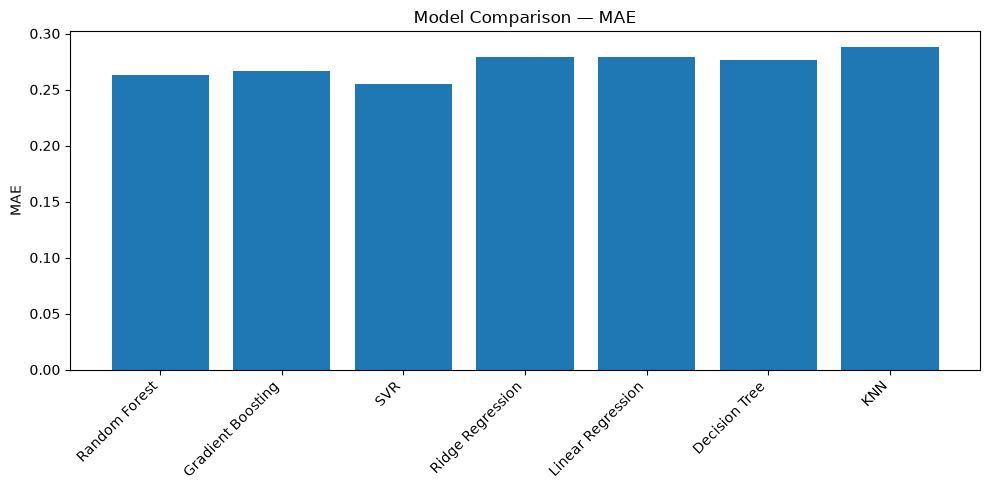

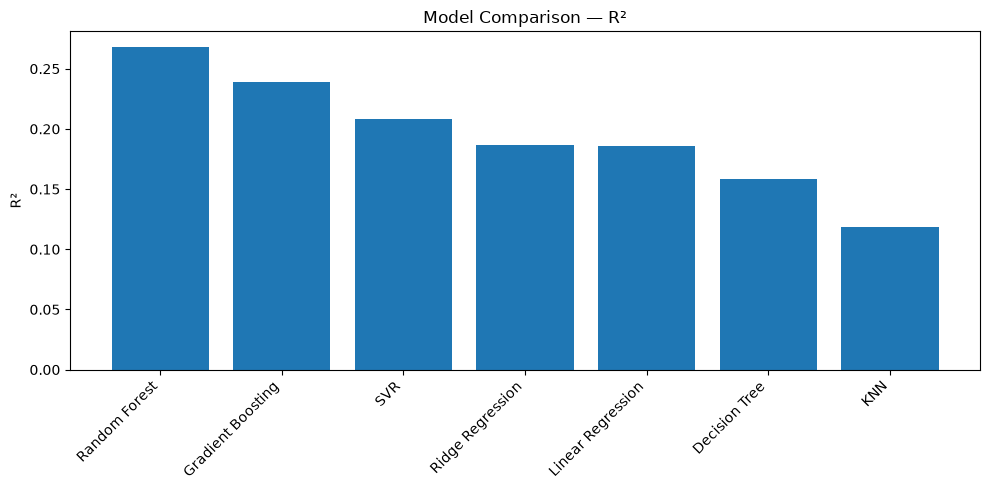

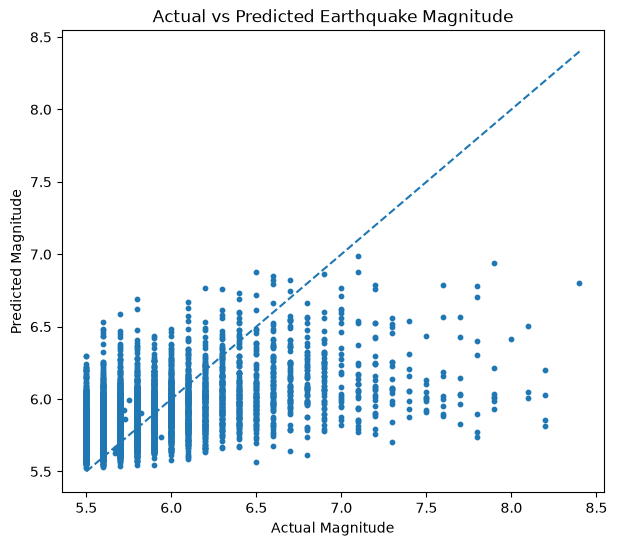

In [ ]:
# MAE comparison
plt.figure(figsize=(10, 5))
plt.bar(model_results["Model"], model_results["MAE"])
plt.ylabel("MAE")
plt.title("Model Comparison — MAE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# R² comparison
plt.figure(figsize=(10, 5))
plt.bar(model_results["Model"], model_results["R2"])
plt.ylabel("R²")
plt.title("Model Comparison — R²")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Actual vs predicted
plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_pred, s=10)

minimum = min(y_test.min(), final_pred.min())
maximum = max(y_test.max(), final_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Magnitude")
plt.ylabel("Predicted Magnitude")
plt.title("Actual vs Predicted Earthquake Magnitude")
plt.show()


## 20. Residual Analysis

### What are we doing?
We calculate and visualize residuals, where residual = actual value − predicted value.

### Why are we doing it?
Residual analysis helps detect systematic prediction errors that may not be obvious from MAE, RMSE, or R² alone.

### What will the output mean?
A good residual plot should show residuals distributed around zero without a strong systematic pattern.


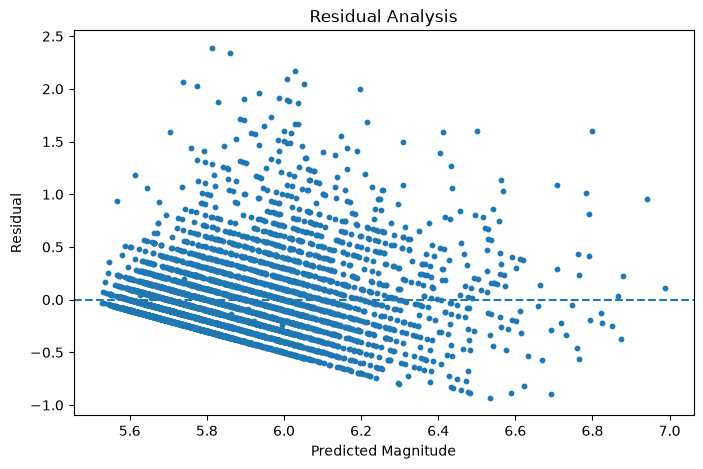

In [ ]:
residuals = y_test - final_pred

plt.figure(figsize=(8, 5))
plt.scatter(final_pred, residuals, s=10)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Magnitude")
plt.ylabel("Residual")
plt.title("Residual Analysis")
plt.show()


## 21. Feature Importance

### What are we doing?
We inspect the feature importance values from the final Random Forest model.

### Why are we doing it?
Feature importance provides an interpretable summary of which transformed predictors contributed most to the fitted model.

### What will the output mean?
A larger importance value means greater predictive contribution within this particular Random Forest. It does **not** mean that the feature causes earthquake magnitude.


,Importance
numeric__Depth Seismic Stations,0.119316
numeric__Latitude,0.091998
numeric__Longitude,0.086272
numeric__Depth,0.083223
numeric__Root Mean Square,0.072864
numeric__Year,0.065797
numeric__Second,0.056961
categorical__Magnitude Type_MB,0.055894
numeric__Azimuthal Gap,0.054878
numeric__Minute,0.054666


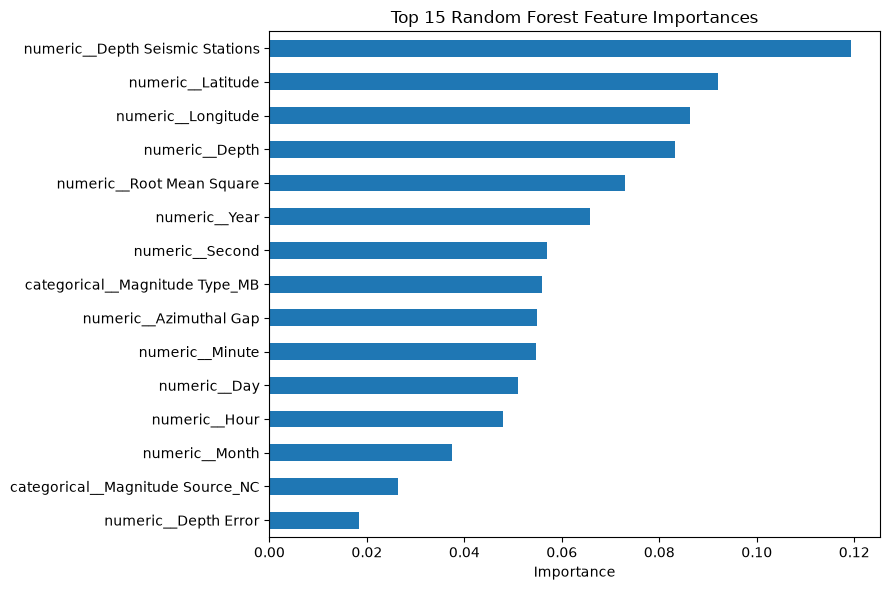

In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.Series(
    final_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

top_features = feature_importance.head(15)

display(top_features.to_frame("Importance"))

plt.figure(figsize=(9, 6))
top_features.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()


## 22. Sample / Unseen Data Prediction

### What are we doing?
We use one observation from the held-out test set as an example and generate its predicted magnitude.

### Why are we doing it?
The assignment requires a sample prediction to demonstrate how the trained model can be used for an unseen observation.

### What will the output mean?
The predicted magnitude is the model's estimate. The actual magnitude is shown only for comparison because this demonstration record comes from the held-out test set.


In [ ]:
sample = X_test.iloc[[0]]

sample_processed = preprocessor.transform(sample)
sample_prediction = final_model.predict(sample_processed)[0]

print("Sample prediction")
print("-----------------")
print("Predicted Magnitude:", sample_prediction)
print("Actual Magnitude   :", y_test.iloc[0])


Sample prediction
-----------------
Predicted Magnitude: 5.701684608794449
Actual Magnitude   : 5.6


## 23. Final Model Selection

### What are we doing?
We summarize the model-selection evidence.

### Why are we doing it?
The final model should be justified using validation and held-out test performance rather than choosing an algorithm arbitrarily.

### What will the output mean?
The table identifies the strongest model according to the test-set metrics, while the cross-validation table provides an additional check of stability. The tuned Random Forest is the final selected model for this implementation.


In [ ]:
best_test_r2_model = model_results.iloc[0]["Model"]
best_test_mae_model = model_results.sort_values("MAE").iloc[0]["Model"]
best_cv_mae_model = cv_results.iloc[0]["Model"]

print("Best model by test R² :", best_test_r2_model)
print("Best model by test MAE:", best_test_mae_model)
print("Best model by CV MAE  :", best_cv_mae_model)

print("\nFinal selected model: Tuned Random Forest")
print("Best parameters:", grid_search.best_params_)


Best model by test R² : Random Forest
Best model by test MAE: SVR
Best model by CV MAE  : SVR

Final selected model: Tuned Random Forest
Best parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 250}


## 24. Final Conclusion

### What was achieved?

An end-to-end machine-learning regression system was developed to predict **earthquake Magnitude**.

The project covered:

1. Dataset understanding and problem definition.
2. Missing-value analysis.
3. Duplicate checking.
4. Outlier identification without blindly deleting valid observations.
5. Exploratory data analysis.
6. Date/time feature engineering.
7. Feature selection.
8. Train-test splitting.
9. Numerical and categorical preprocessing.
10. Multiple regression models.
11. Ridge regularization.
12. Five-fold cross-validation.
13. Random Forest hyperparameter tuning.
14. Final evaluation using MAE, RMSE, and R².
15. Model comparison and diagnostic plots.
16. Feature-importance analysis.
17. Sample prediction on unseen test data.


